In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
angles = []

In [2]:
from math import sin, cos, pi

In [87]:
def crown(npoints = 10, inner = True):
    points = []
    
    angles = np.linspace(0, pi, npoints)
    for a in angles:
        points.append((cos(a), sin(a)))

    points.reverse()
    if inner:
        points = points[1:-1]
    return points

In [88]:
points = crown(9)
xs = [p[0] for p in points]
ys = [p[1] for p in points]

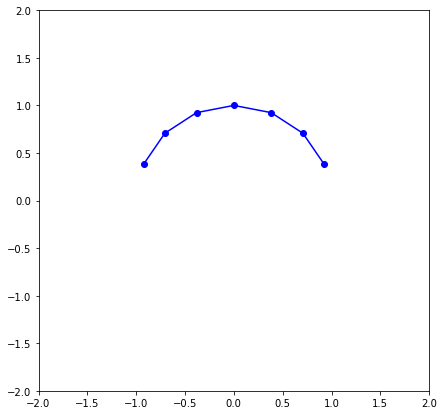

In [89]:
fig = plt.figure(figsize = (7,7))
ax = plt.axes()
ax.set(
    xlim = (-2,2),
    ylim = (-2,2)
)
ax.plot(xs,ys, "-ob")

In [90]:
def rotate(points, angle = pi/2):
    R = np.array([
        [cos(angle), -sin(angle)],
        [sin(angle), cos(angle)]
    ])
    
    retval = []
    for p in points:
        retval.append(R @ np.array(p))
    return retval
    

In [91]:
rpoints = []
for p in points:
    rpoints.append(R@p)
#     print(f"{p} -> {R@p}")

In [92]:
rpoints = rotate(points, angle = pi/3)
xs = [p[0] for p in rpoints]
ys = [p[1] for p in rpoints]

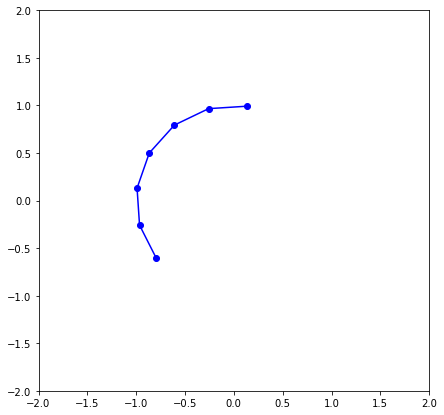

In [93]:
fig = plt.figure(figsize = (7,7))
ax = plt.axes()
ax.set(
    xlim = (-2,2),
    ylim = (-2,2)
)
ax.plot(xs,ys, "-ob")

In [94]:
A = np.array((0, 0))
B = np.array((7, 2))

In [95]:
middle = (A+B)/2

direction = B - middle

symmetry = middle + rotate([-direction, (0,0), direction])

In [96]:
symmetry

array([[ 4.5, -2.5],
       [ 3.5,  1. ],
       [ 2.5,  4.5]])

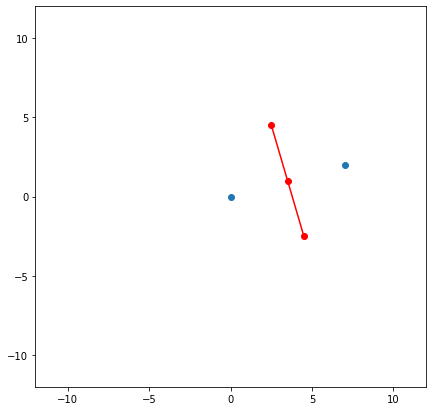

In [97]:
fig = plt.figure(figsize = (7,7))
ax = plt.axes()
ax.set(
    xlim = (-12,12),
    ylim = (-12,12)
)

ax.scatter(
    [A[0], B[0]],
    [A[1], B[1]]
)
ax.plot(
    [symmetry[0][0], symmetry[1][0], symmetry[2][0]],
    [symmetry[0][1], symmetry[1][1], symmetry[2][1]],
    "-or"
)
# ax.plot(xs,ys, "-ob")

In [98]:
def symmetry(A, B):
    A = np.array(A)
    B = np.array(B)
    
    middle = (A+B)/2
    direction = B - middle
    symmetry = middle + rotate([-direction, (0,0), direction], angle = pi/2)
    
    return symmetry

In [99]:
middle = (A[0]/2 + B[0]/2, A[1]/2 + B[1]/2)
direction 

array([3.5, 1. ])

In [100]:
def is_same_side(init_point, centroid, point1, point2):
    k = (point2[1] - point1[1]) / (point2[0] - point1[0]) # line equation: y - kx - n = 0 
    n = point1[1] - k*point1[0]

    side_centroid = np.sign( centroid[1] - k * centroid[0] - n ) # half-plane detection
    side_init = np.sign( init_point[1] - k * init_point[0] - n )

    return side_centroid == side_init # same or different sides of point1-point2 line

In [101]:
centroid = (0, 0)
A = (-4, 4)
B = (3, 8)
symm = symmetry(A, B)
middle = symm[1]
symm

array([[ 1.5,  2.5],
       [-0.5,  6. ],
       [-2.5,  9.5]])

In [102]:
print(is_same_side(symm[0], centroid, A, B))
print(is_same_side(symm[2], centroid, A, B))

True
False


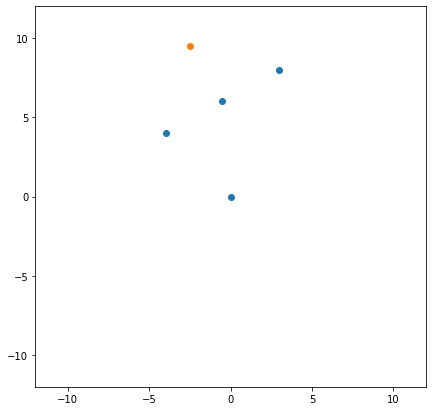

In [103]:
fig = plt.figure(figsize = (7,7))
ax = plt.axes()
ax.set(
    xlim = (-12,12),
    ylim = (-12,12)
)

ax.scatter(
    [A[0], B[0], centroid[0], middle[0]],
    [A[1], B[1], centroid[1], middle[1]]
)

for p in [symm[0], symm[2]]:
    if not is_same_side(p, centroid, A, B):
        ax.scatter(p[0], p[1])

plt.show()

In [104]:
outer = None
for p in [symm[0], symm[2]]:
    if not is_same_side(p, centroid, A, B):
        outer = p

In [105]:
outer

array([-2.5,  9.5])

In [106]:
x = B - middle
y = outer - middle

In [107]:
def projection(points, x, y, center):
    retval = []
    for p in points:
        newcoord = center + p[0] * x + p[1] * y
        retval.append(newcoord)
    
    return retval

In [108]:
ppoints = projection(points, x, y, middle)

In [109]:
ppoints

[array([-4.49894523,  5.49163295]),
 array([-4.3890873 ,  7.06066017]),
 array([-3.68715108,  8.4682115 ]),
 array([-2.5,  9.5]),
 array([-1.00836705,  9.99894523]),
 array([0.56066017, 9.8890873 ]),
 array([1.9682115 , 9.18715108])]

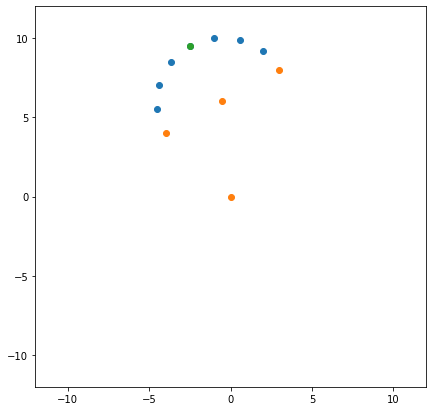

In [110]:
fig = plt.figure(figsize = (7,7))
ax = plt.axes()
ax.set(
    xlim = (-12,12),
    ylim = (-12,12)
)

xs = [p[0] for p in ppoints]
ys = [p[1] for p in ppoints]
ax.scatter(xs, ys)

ax.scatter(
    [A[0], B[0], centroid[0], middle[0]],
    [A[1], B[1], centroid[1], middle[1]]
)

for p in [symm[0], symm[2]]:
    if not is_same_side(p, centroid, A, B):
        ax.scatter(p[0], p[1])

plt.show()